# 02 · Structural MRI EDA
> *MRI gives us a detailed picture of brain structure — which sequences were acquired, their quality, and overall grey matter volume.*

## Background: What is Structural MRI?

**MRI (Magnetic Resonance Imaging)** uses magnetic fields and radio waves to produce detailed images of the brain without radiation.

**Key sequences acquired in PPMI:**

| Sequence | Purpose |
|----------|---------|
| **T1-weighted** | High-resolution anatomical brain structure — gold standard for measuring brain volumes and cortical thickness |
| **T2-weighted / FLAIR** | Highlights fluid; good for detecting lesions and white matter abnormalities |
| **DTI (Diffusion Tensor)** | Measures direction of water diffusion along white matter tracts |
| **Resting-state fMRI** | Captures brain activity at rest via blood oxygenation changes |
| **NM-MRI (Neuromelanin)** | Specifically images the Substantia Nigra — the PD-affected region |

**Why MRI in PD?** PD causes measurable structural changes:
- Shrinkage of striatum, hippocampus, cortex
- White matter tract disruption
- Substantia Nigra changes visible on NM-MRI

**What we measure:** Not the raw scan — but derived numbers: volumes, thicknesses, quality metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
mri_log  = pd.read_csv(DATA_DIR / 'Magnetic_Resonance_Imaging__MRI__12Nov2026.csv')
mri_meta = pd.read_csv(DATA_DIR / 'Xing_Core_Lab_-_MRI_acquisition_metadata_12Nov2026.csv')
mriqc    = pd.read_csv(DATA_DIR / 'MRIQC_12Nov2026.csv')
gmvol    = pd.read_csv(DATA_DIR / 'Grey_Matter_Volume_12Nov2026.csv')
for name, df in [('MRI Log', mri_log), ('Acquisition Metadata', mri_meta),
                 ('MRIQC', mriqc), ('Grey Matter Volume', gmvol)]:
    print(f'{name:30s}: {len(df):>6,} rows | {df["PATNO"].nunique()} participants')

MRI Log                       : 13,658 rows | 6649 participants
Acquisition Metadata          :  8,811 rows | 4871 participants
MRIQC                         :  1,740 rows | 1740 participants
Grey Matter Volume            :    363 rows | 137 participants


## Column Reference

### MRI Log (`Magnetic_Resonance_Imaging__MRI__`)
| Column | Meaning |
|--------|---------|
| `MRICMPLT` | MRI scan completed: 1=Yes, 0=No |
| `MRIWDTI` | DTI sequences included: 1=Yes, 0=No |
| `MRIWRSS` | Resting-state fMRI sequences included: 1=Yes, 0=No |
| `MRIRSLT` | MRI result code |

### Acquisition Metadata (`Xing_Core_Lab_-_MRI_acquisition_metadata`)
| Column | Meaning |
|--------|---------|
| `MRI_SEQ_T1_WEIGHTED` | T1-weighted sequence acquired: Yes/No |
| `MRI_SEQ_T2_WEIGHTED` | T2-weighted / FLAIR sequence acquired: Yes/No |
| `MRI_SEQ_DTI` | DTI sequence acquired: Yes/No |
| `MRI_SEQ_RS` | Resting-state fMRI acquired: Yes/No |
| `MRI_SEQ_NM_MT` | Neuromelanin sequence acquired: Yes/No |
| `MRI_IMAGE_ACCEPTABLE` | Overall image quality: Yes/No |

### MRIQC (Quality Control Metrics)
These are automated image quality measures. They tell you if a scan is worth using for analysis.

| Column | Meaning | Good direction |
|--------|---------|---------------|
| `cjv` | Coefficient of Joint Variation — tissue intensity uniformity | Lower = better |
| `cnr` | Contrast-to-Noise Ratio — how well GM/WM are differentiated | Higher = better |
| `efc` | Entropy Focus Criterion — sharpness, low = less motion | Lower = better |
| `fber` | Foreground-to-Background Energy Ratio | Higher = better |
| `snr_total` | Overall Signal-to-Noise Ratio | Higher = better |
| `snr_gm` | SNR in grey matter | Higher = better |
| `snr_wm` | SNR in white matter | Higher = better |
| `fwhm_avg` | Full-Width Half-Maximum — spatial smoothness in mm | Lower = sharper |
| `icvs_gm` | Grey matter as fraction of intracranial volume | — |
| `icvs_wm` | White matter as fraction of intracranial volume | — |
| `icvs_csf` | CSF as fraction of intracranial volume | — |

### Grey Matter Volume
| Column | Meaning |
|--------|---------|
| `GM_VOLUME` | Total grey matter volume in mm³ |
| `IMAGEID` | Unique identifier for the scan image |
| `MRIDATE` | Date of MRI scan |

## 1 · MRI Scan Completion per Visit

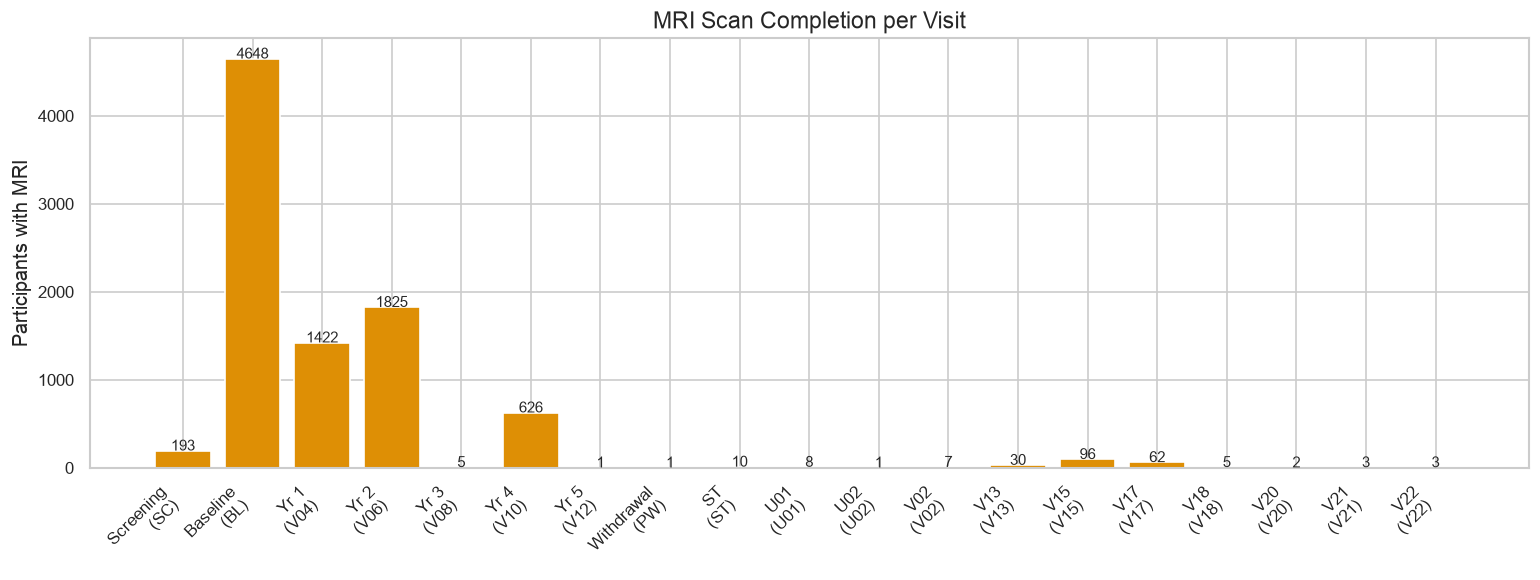

In [4]:
completed = mri_log[mri_log['MRICMPLT'] == 1]
visits = ordered_visits(mri_log['EVENT_ID'])
vc = completed.groupby('EVENT_ID')['PATNO'].nunique().reindex(visits).dropna()

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(vc)), vc.values, color=sns.color_palette('colorblind')[1])
ax.set_xticks(range(len(vc)))
ax.set_xticklabels([f'{VISIT_LABELS.get(v,v)}\n({v})' for v in vc.index], rotation=45, ha='right')
ax.set_ylabel('Participants with MRI'); ax.set_title('MRI Scan Completion per Visit')
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+3, str(int(v)), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

## 2 · Which MRI Sequences Were Acquired?

Not every participant gets every sequence. This shows what fraction had each sequence type.

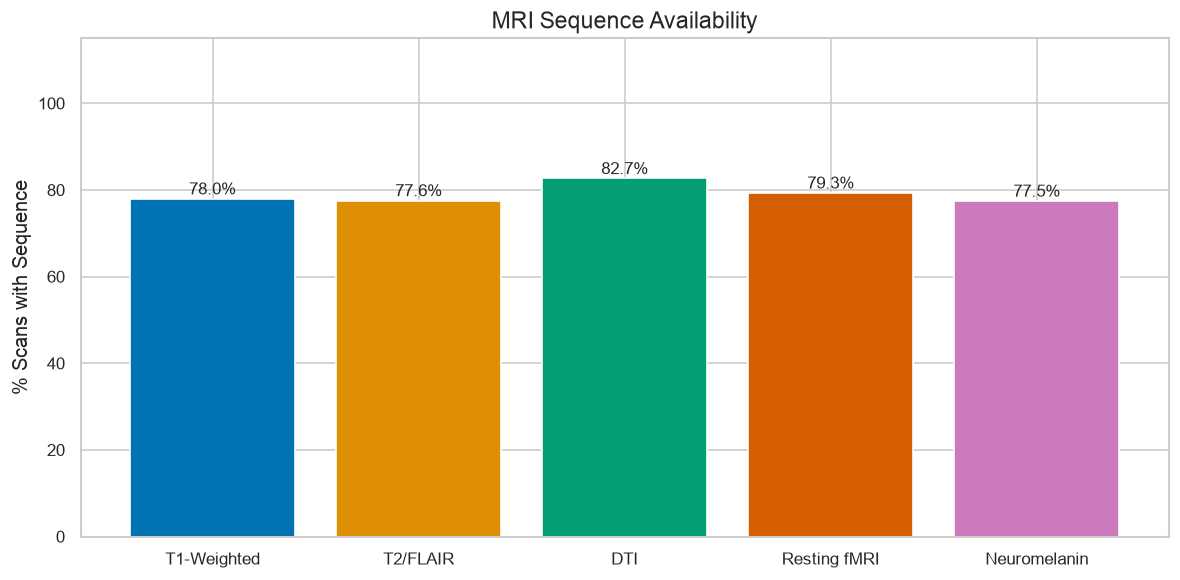

In [5]:
seq_cols = {'T1-Weighted': 'MRI_SEQ_T1_WEIGHTED', 'T2/FLAIR': 'MRI_SEQ_T2_WEIGHTED',
            'DTI': 'MRI_SEQ_DTI', 'Resting fMRI': 'MRI_SEQ_RS', 'Neuromelanin': 'MRI_SEQ_NM_MT'}
seq_cols = {k: v for k, v in seq_cols.items() if v in mri_meta.columns}

yes_pct = {k: (mri_meta[v] == 'Yes').mean()*100 for k, v in seq_cols.items()}
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(yes_pct.keys(), yes_pct.values(),
              color=sns.color_palette('colorblind', len(yes_pct)))
ax.set_ylabel('% Scans with Sequence'); ax.set_title('MRI Sequence Availability')
ax.set_ylim(0, 115)
for b, (k, v) in zip(bars, yes_pct.items()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout(); plt.show()

## 3 · Image Quality Acceptance Rate

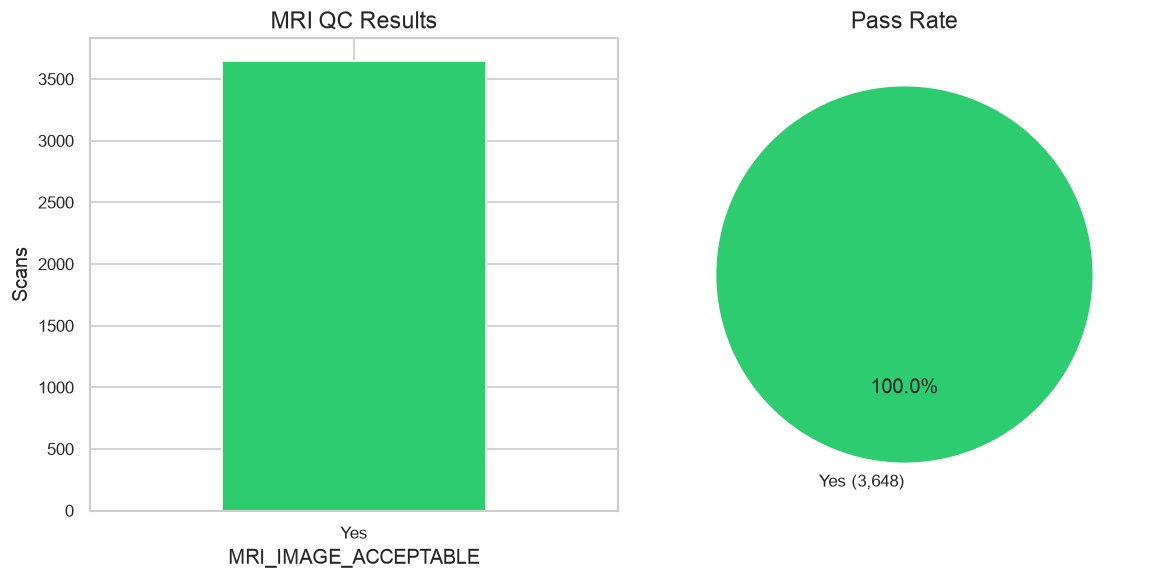

Acceptance: 41.4%


In [6]:
if 'MRI_IMAGE_ACCEPTABLE' in mri_meta.columns:
    qc = mri_meta['MRI_IMAGE_ACCEPTABLE'].value_counts()
    colors = ['#2ecc71' if 'Yes' in str(k) else '#e74c3c' for k in qc.index]
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    qc.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
    axes[0].set_title('MRI QC Results'); axes[0].set_ylabel('Scans')
    axes[0].tick_params(axis='x', rotation=0)
    axes[1].pie(qc.values, labels=[f'{k} ({v:,})' for k,v in qc.items()],
                colors=colors, autopct='%1.1f%%', startangle=90)
    axes[1].set_title('Pass Rate')
    plt.tight_layout(); plt.show()
    print(f'Acceptance: {qc.get("Yes",0)/len(mri_meta)*100:.1f}%')

## 4 · MRIQC — Automated Image Quality Metrics

MRIQC is a tool that automatically extracts quality metrics from T1-weighted MRI. We plot the four most important summary metrics.

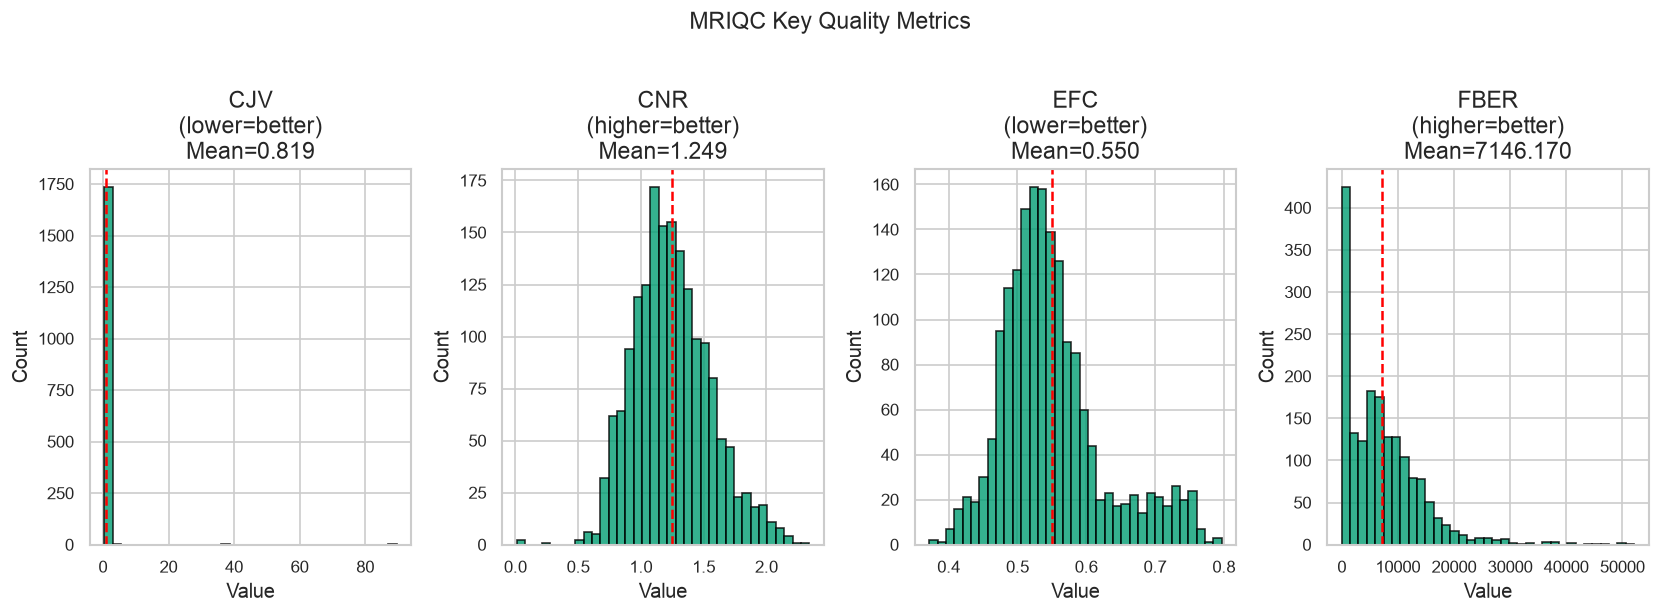

             cjv        cnr        efc        fber
count  1740.0000  1740.0000  1740.0000   1740.0000
mean      0.8187     1.2495     0.5498   7146.1696
std       2.3108     0.3055     0.0742   6903.6724
min       0.4294     0.0112     0.3718     -1.0000
25%       0.6452     1.0377     0.5017   1596.2875
50%       0.7248     1.2307     0.5371   6007.0600
75%       0.8111     1.4363     0.5804  10558.6000
max      89.6024     2.3408     0.7969  52107.7000


In [7]:
key_metrics = {'CJV\n(lower=better)': 'cjv', 'CNR\n(higher=better)': 'cnr',
               'EFC\n(lower=better)': 'efc', 'FBER\n(higher=better)': 'fber'}
key_metrics = {k: v for k, v in key_metrics.items() if v in mriqc.columns}

fig, axes = plt.subplots(1, len(key_metrics), figsize=(14, 5))
for ax, (label, col) in zip(axes, key_metrics.items()):
    data = mriqc[col].dropna()
    data.hist(bins=35, ax=ax, edgecolor='black', alpha=0.8, color=sns.color_palette('colorblind')[2])
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.5)
    ax.set_title(f'{label}\nMean={data.mean():.3f}')
    ax.set_xlabel('Value'); ax.set_ylabel('Count')
plt.suptitle('MRIQC Key Quality Metrics', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()
print(mriqc[list(key_metrics.values())].describe().round(4))

## 5 · SNR by Tissue Type

Signal-to-Noise Ratio broken down by brain tissue: Grey Matter (GM), White Matter (WM), and CSF.

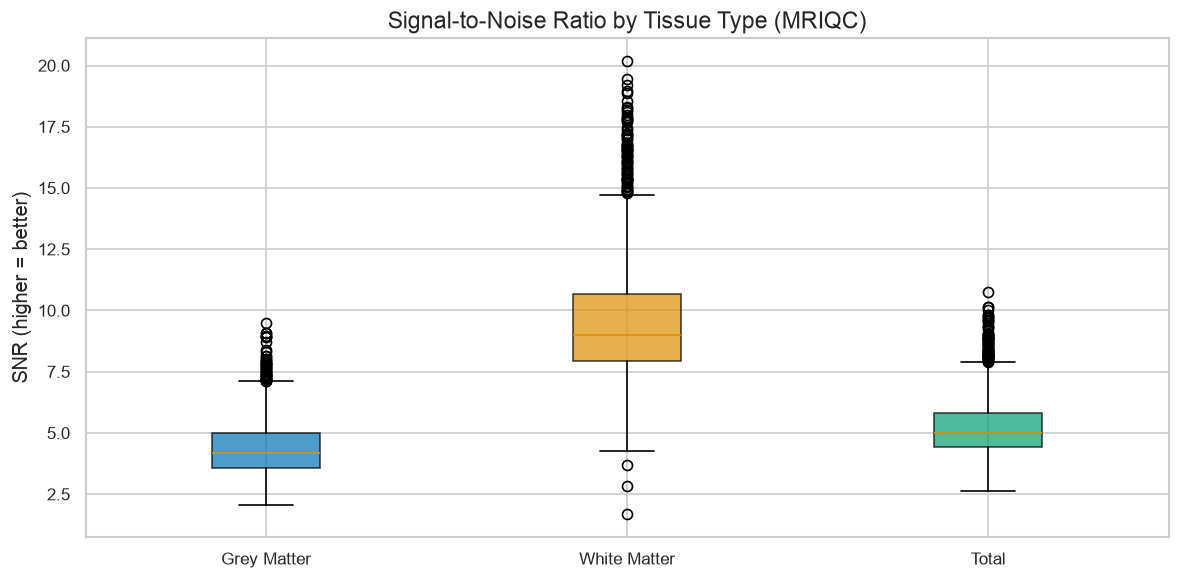

In [8]:
snr_cols = {'Grey Matter': 'snr_gm', 'White Matter': 'snr_wm', 'Total': 'snr_total'}
snr_cols = {k: v for k, v in snr_cols.items() if v in mriqc.columns}

if snr_cols:
    fig, ax = plt.subplots(figsize=(10, 5))
    data = [mriqc[v].dropna().values for v in snr_cols.values()]
    bp = ax.boxplot(data, patch_artist=True, boxprops=dict(alpha=0.7))
    ax.set_xticks(range(1, len(snr_cols)+1))
    ax.set_xticklabels(list(snr_cols.keys()))
    colors = sns.color_palette('colorblind', len(snr_cols))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    ax.set_title('Signal-to-Noise Ratio by Tissue Type (MRIQC)')
    ax.set_ylabel('SNR (higher = better)')
    plt.tight_layout(); plt.show()

## 6 · Grey Matter Volume Distribution

Total grey matter volume in mm³, extracted from T1 MRI. Normal adult GM volume is roughly 500,000–1,000,000 mm³.

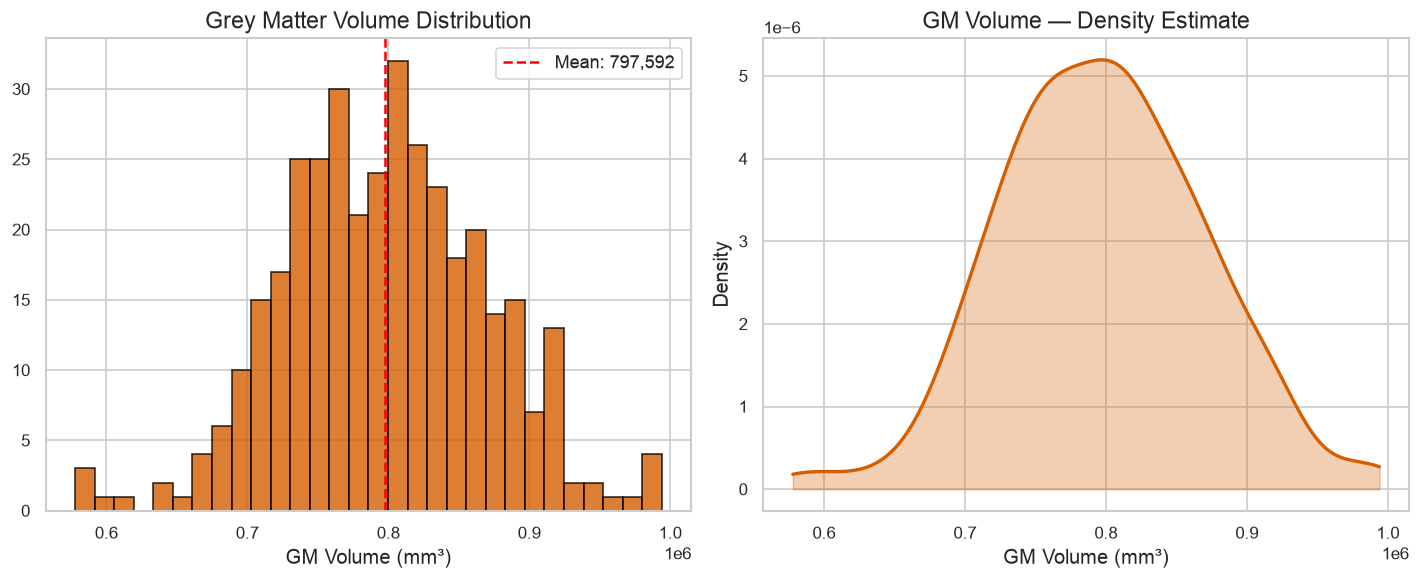

count       363.0
mean     797592.0
std       72157.0
min      577870.0
25%      746751.0
50%      797547.0
75%      846184.0
max      994045.0
Name: GM_VOLUME, dtype: float64


In [9]:
gm = gmvol['GM_VOLUME'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
gm.hist(bins=30, ax=axes[0], edgecolor='black', alpha=0.8, color=sns.color_palette('colorblind')[3])
axes[0].axvline(gm.mean(), color='red', linestyle='--', label=f'Mean: {gm.mean():,.0f}')
axes[0].set_title('Grey Matter Volume Distribution')
axes[0].set_xlabel('GM Volume (mm³)'); axes[0].legend()
# KDE overlay
from scipy.stats import gaussian_kde
kde = gaussian_kde(gm)
x = np.linspace(gm.min(), gm.max(), 200)
axes[1].plot(x, kde(x), color=sns.color_palette('colorblind')[3], linewidth=2)
axes[1].fill_between(x, kde(x), alpha=0.3, color=sns.color_palette('colorblind')[3])
axes[1].set_title('GM Volume — Density Estimate')
axes[1].set_xlabel('GM Volume (mm³)'); axes[1].set_ylabel('Density')
plt.tight_layout(); plt.show()
print(gm.describe().round(0))

## 7 · Grey Matter Volume by Visit

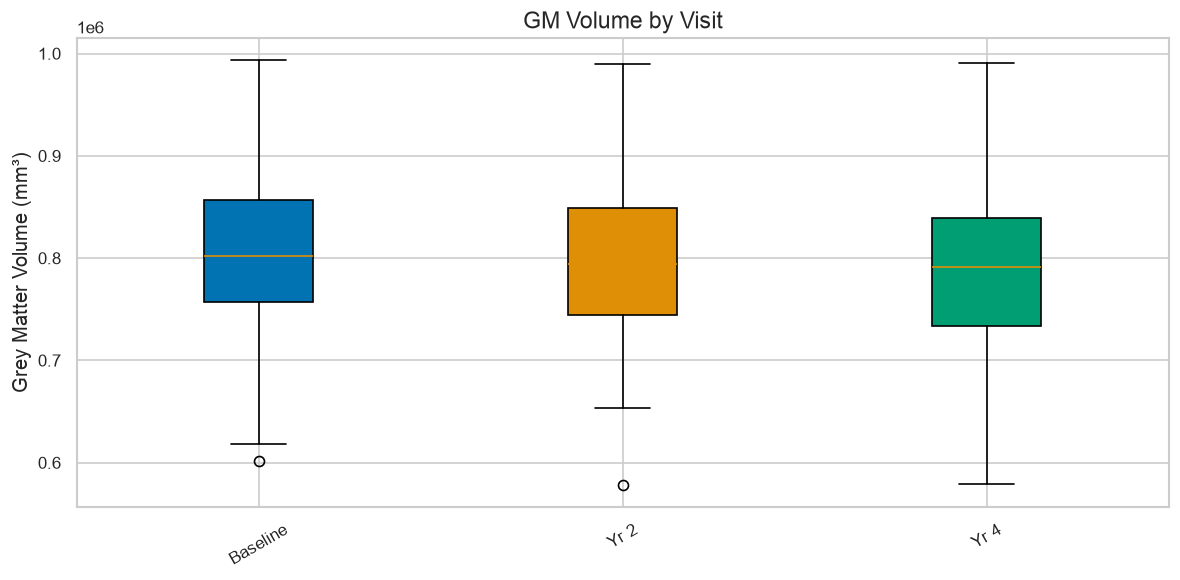

In [10]:
if 'EVENT_ID' in gmvol.columns:
    visits = ordered_visits(gmvol['EVENT_ID'])
    present = [v for v in visits if v in gmvol['EVENT_ID'].unique()]
    fig, ax = plt.subplots(figsize=(10, 5))
    data = [gmvol[gmvol['EVENT_ID']==v]['GM_VOLUME'].dropna().values for v in present]
    bp = ax.boxplot(data, patch_artist=True)
    ax.set_xticks(range(1, len(present)+1))
    ax.set_xticklabels([VISIT_LABELS.get(v,v) for v in present])
    colors = sns.color_palette('colorblind', len(present))
    for patch, c in zip(bp['boxes'], colors): patch.set_facecolor(c)
    ax.set_ylabel('Grey Matter Volume (mm³)')
    ax.set_title('GM Volume by Visit')
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.show()

## Key Takeaways

- **T1-weighted MRI is near-universal** in PPMI; DTI and resting fMRI are available for subsets
- **High QC acceptance rate** means most MRI data is usable
- **MRIQC metrics** let you filter out poor-quality scans before analysis — CJV and CNR are the most useful
- **Grey matter volume** is a global measure of brain atrophy — expect subtle decline in PD over years
- **Next step:** FreeSurfer EDA digs into regional cortical and subcortical structure